本实验是探索xor的隐状态几何表征，看看神经网络是怎么理解xor问题的；

In [58]:
import torch
import torch.nn as nn
import numpy as np

In [59]:
def generate_xor_data(n_samples=1000, noise=0.0, seed=None):
    rng = np.random.default_rng(seed)
    # 随机生成 0/1 输入
    X = rng.integers(0, 2, size=(n_samples, 2))
    # XOR 标签
    y = (X[:, 0] ^ X[:, 1]).astype(np.float32).reshape(-1, 1)
    # 可选：给输入加高斯噪声
    if noise > 0:
        X = X + rng.normal(0, noise, size=X.shape).astype(np.float32)
    return X, y

In [60]:
class XORNet(nn.Module):
    def __init__(self, input_dim=2, hidden_dim=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x)

In [61]:
# 训练
X, y = generate_xor_data(n_samples=1000)
X = torch.from_numpy(X).float()
y = torch.from_numpy(y).float()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = XORNet(input_dim=2, hidden_dim=3).to(device)
X = X.to(device)
y = y.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters())

epochs = 1000
for epoch in range(epochs):
    model.train()
    # 前向
    logits = model(X)               # (N, 1)
    loss = criterion(logits, y)
    # 反向
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # 打印
    if (epoch + 1) % 100 == 0:
        with torch.no_grad():
            pred = (torch.sigmoid(logits) > 0.5).float()
            acc = (pred == y).float().mean().item()
        print(f"Epoch {epoch+1:4d} | loss={loss.item():.4f} | acc={acc:.4f}")

Epoch  100 | loss=0.6979 | acc=0.4870
Epoch  200 | loss=0.6880 | acc=0.2420
Epoch  300 | loss=0.6671 | acc=0.7550
Epoch  400 | loss=0.6356 | acc=0.7550
Epoch  500 | loss=0.5988 | acc=0.7550
Epoch  600 | loss=0.5650 | acc=0.7550
Epoch  700 | loss=0.5377 | acc=0.7550
Epoch  800 | loss=0.5184 | acc=0.7550
Epoch  900 | loss=0.5054 | acc=0.7550
Epoch 1000 | loss=0.4971 | acc=0.7550


Epoch  100 | loss=0.4918
Epoch  200 | loss=0.4881
Epoch  300 | loss=0.4856
Epoch  400 | loss=0.4838
Epoch  500 | loss=0.4826
Epoch  600 | loss=0.4815
Epoch  700 | loss=0.4808
Epoch  800 | loss=0.4802
Epoch  900 | loss=0.4798
Epoch 1000 | loss=0.4794


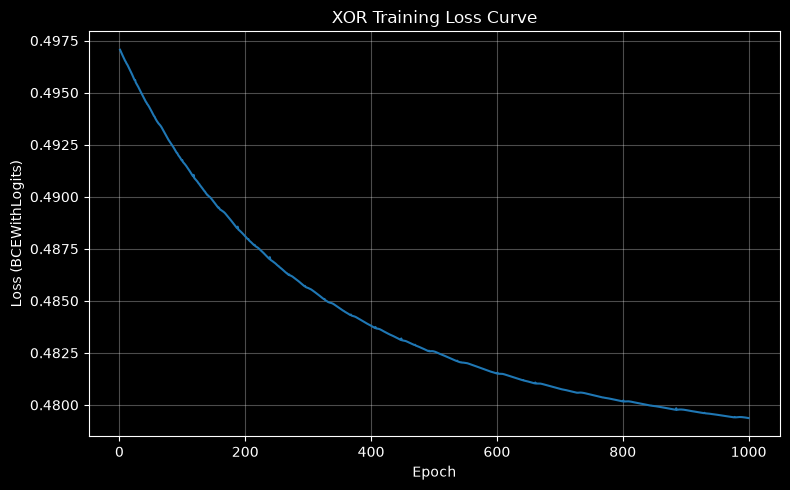

In [62]:
import matplotlib.pyplot as plt

# ============ 训练并记录 loss ============
epochs = 1000
loss_history = []

for epoch in range(epochs):
    model.train()
    logits = model(X)
    loss = criterion(logits, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())   # ← 记录

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1:4d} | loss={loss.item():.4f}")

# ============ 绘制 loss 曲线 ============
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, color='tab:blue', linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('Loss (BCEWithLogits)')
plt.title('XOR Training Loss Curve')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
# 真值表验证
model.eval()
with torch.no_grad():
    test_X = torch.tensor([[0,0],[0,1],[1,0],[1,1]], dtype=torch.float32).to(device)
    probs = torch.sigmoid(model(test_X)).squeeze().cpu().numpy()
    print("\nXOR 验证:")
    for inp, p in zip(test_X.cpu().numpy(), probs):
        print(f"  {inp.astype(int)} -> {p:.3f}  (pred={int(p>0.5)})")


XOR 验证:
  [0 0] -> 0.326  (pred=0)
  [0 1] -> 0.990  (pred=1)
  [1 0] -> 0.326  (pred=0)
  [1 1] -> 0.326  (pred=0)
